# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='blue'> Profesor: Alejandro I. Trejo-Castro</font>

### 4.1. Distribuciones de probabilidad y correlación.

*Bienvenidos* a este jupyter notebook que nos será de utilidad para comprender las operaciones básicas y códigos introductorios en Python.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

### 1. Distribución Binomial. ¿Cuántas respuestas acertamos al adivinar?

#### Un kahoot tiene 10 preguntas, cada una con 4 opciones y una sola correcta. Suponemos respuestas independientes.

In [1]:
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
sns.set_theme(style="whitegrid")

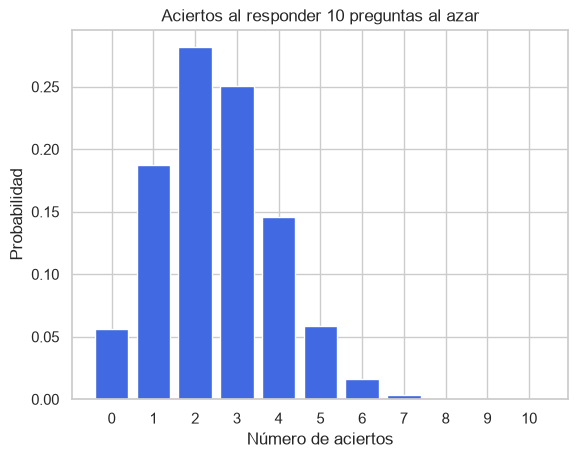

Aciertos esperados: 2.5


In [2]:
n = 10      # Número de preguntas
p = 0.25    # Probabilidad de acertar cada pregunta

aciertos = np.arange(n + 1)
probabilidades = stats.binom.pmf(aciertos, n, p)

plt.bar(aciertos, probabilidades, color="royalblue")
plt.xticks(aciertos)
plt.xlabel("Número de aciertos")
plt.ylabel("Probabilidad")
plt.title("Aciertos al responder 10 preguntas al azar")
plt.show()

print(f"Aciertos esperados: {n * p:.1f}")

#### Exactamente 3 aciertos

In [3]:
print(f"Probabilidad de acertar exactamente 3: {stats.binom.pmf(3, n, p):.1%}")

Probabilidad de acertar exactamente 3: 25.0%


#### Como máximo 3 aciertos

In [4]:
print(f"Como máximo 3 aciertos: {stats.binom.cdf(3, n, p):.2%}")

Como máximo 3 aciertos: 77.59%


In [5]:
stats.binom.pmf(0, n, p)+stats.binom.pmf(1, n, p)+stats.binom.pmf(2, n, p)+stats.binom.pmf(3, n, p)

0.7758750915527342

#### Más de 3 aciertos

In [6]:
print(f"Más de 3 aciertos: {1 - stats.binom.cdf(3, n, p):.2%}")

Más de 3 aciertos: 22.41%


In [7]:
# 1. ¿Cuál es la probabilidad de obtener como máximo 2 aciertos?
print(f"1. {stats.binom.cdf(2, n, p):.2%}")
# 2. ¿Cuál es la probabilidad de obtener más de 5 aciertos?
print(f"2. {1 - stats.binom.cdf(5, n, p):.2%}")
# 3. ¿Cuál es la probabilidad de obtener al menos 6 aciertos? ¿Es igual a la anterior?
print(f"3. {1 - stats.binom.cdf(5, n, p):.2%}")
# 4. ¿Cuál es la probabilidad de obtener entre 3 y 5 aciertos, incluidos ambos?
print(f"4. {stats.binom.cdf(5, n, p) - stats.binom.cdf(2, n, p):.2%}")

1. 52.56%
2. 1.97%
3. 1.97%
4. 45.47%


### Distribución normal: valores alrededor de un promedio

#### Simulamos estaturas con media de 170 cm y desviación estándar de 10 cm

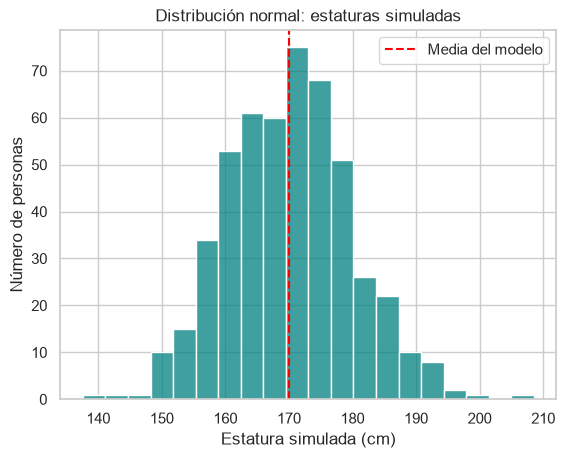

In [8]:
media = 170
desviacion = 10

estaturas = np.random.normal(media, desviacion, 500)

sns.histplot(estaturas, bins=20, color="teal")
plt.axvline(media, color="red", linestyle="--", label="Media del modelo")
plt.xlabel("Estatura simulada (cm)")
plt.ylabel("Número de personas")
plt.title("Distribución normal: estaturas simuladas")
plt.legend()
plt.show()

#### Medir menos de 180 cm

In [9]:
probabilidad = stats.norm.cdf(180, media, desviacion)
print(f"Probabilidad de medir menos de 180 cm: {probabilidad:.1%}")

Probabilidad de medir menos de 180 cm: 84.1%


#### Medir más de 180 cm

In [10]:
print(f"Medir más de 180 cm: {1 - stats.norm.cdf(180, media, desviacion):.2%}")

Medir más de 180 cm: 15.87%


In [11]:
# 1. ¿Cuál es la probabilidad de medir menos de 160 cm?
print(f"1. {stats.norm.cdf(160, media, desviacion):.2%}")
# 2. ¿Cuál es la probabilidad de medir más de 175 cm?
print(f"2. {1 - stats.norm.cdf(175, media, desviacion):.2%}")
# 3. ¿Cuál es la probabilidad de medir entre 160 cm y 180 cm?
print(f"3. {stats.norm.cdf(180, media, desviacion) - stats.norm.cdf(160, media, desviacion):.2%}")
# 4. ¿Qué resultado esperas al calcular stats.norm.cdf(170, media, desviacion)?
print(f"4. {stats.norm.cdf(170, media, desviacion):.2%}")

1. 15.87%
2. 30.85%
3. 68.27%
4. 50.00%


### Correlación: ¿más publicidad se relaciona con más ventas?

Pearson: 0.87 | p = 1.02e-31
Spearman: 0.89 | p = 6.15e-35
Kendall: 0.71 | p = 2.49e-25


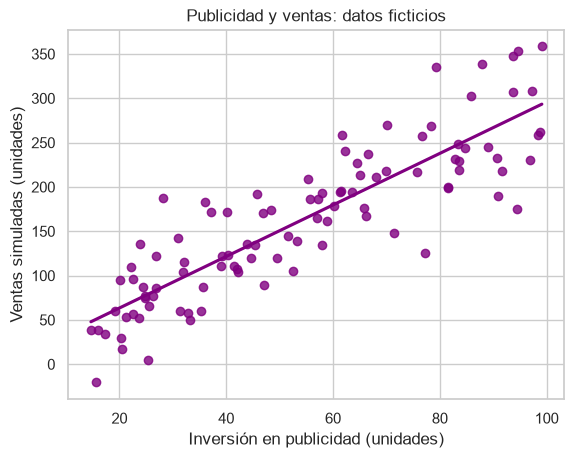

In [12]:
publicidad = np.random.uniform(10, 100, 100)
ventas = 3 * publicidad + np.random.normal(0, 40, 100)

for nombre, funcion in [("Pearson", stats.pearsonr),
                        ("Spearman", stats.spearmanr),
                        ("Kendall", stats.kendalltau)]:
    coeficiente, p_valor = funcion(publicidad, ventas)
    print(f"{nombre}: {coeficiente:.2f} | p = {p_valor:.2e}")

sns.regplot(x=publicidad, y=ventas, color="purple", ci=None)
plt.xlabel("Inversión en publicidad (unidades)")
plt.ylabel("Ventas simuladas (unidades)")
plt.title("Publicidad y ventas: datos ficticios")
plt.show()

Pearson correlation coefficient: 0.869, p-value: 0.000
Spearman correlation coefficient: 0.889, p-value: 6.155e-35
Kendall correlation coefficient: 0.705, p-value: 2.490e-25


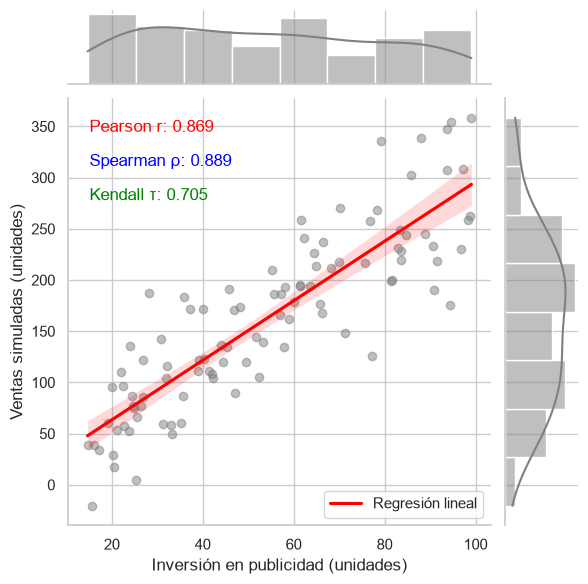

In [13]:
x = publicidad
y = ventas

# Pearson correlation (linear relationship)
pearson_corr, pearson_p = stats.pearsonr(x, y)
print(f"Pearson correlation coefficient: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")

# Spearman correlation (monotonic relationship)
spearman_corr, spearman_p = stats.spearmanr(x, y)
print(f"Spearman correlation coefficient: {spearman_corr:.3f}, p-value: {spearman_p:.3e}")

# Kendall correlation (rank correlation)
kendall_corr, kendall_p = stats.kendalltau(x, y)
print(f"Kendall correlation coefficient: {kendall_corr:.3f}, p-value: {kendall_p:.3e}")

# Create a jointplot with correlation annotation
# Store data in a Pandas DataFrame for easier plotting with Seaborn
df = pd.DataFrame({'X_values': x, 'Y_values': y})

# Use seaborn.jointplot to visualize the relationship
# The 'kind' parameter can be 'scatter', 'reg', 'hex', 'kde', etc.
g = sns.jointplot(data=df, x="X_values", y="Y_values", kind="reg",
                 color = "gray",
                 scatter_kws={"alpha": 0.5},
    line_kws={"color": "red", "label": "Regresión lineal"},
    ci=95)

# Manually add the correlation values as annotations to the plot
# You can choose which correlation value to display, for example, Spearman
g.ax_joint.text(
    0.05, 0.95, f'Pearson r: {pearson_corr:.3f}',
    transform=g.ax_joint.transAxes, color="red", va="top"
)
g.ax_joint.text(
    0.05, 0.87, f'Spearman ρ: {spearman_corr:.3f}',
    transform=g.ax_joint.transAxes, color="blue", va="top"
)
g.ax_joint.text(
    0.05, 0.79, f'Kendall τ: {kendall_corr:.3f}',
    transform=g.ax_joint.transAxes, color="green", va="top"
)

g.ax_joint.legend(loc="lower right")
plt.xlabel("Inversión en publicidad (unidades)")
plt.ylabel("Ventas simuladas (unidades)")
plt.show()
